# Research Assistant Agent Overview

This notebook provides an interactive way to explore the LangGraph agent.

### 1. Environment Setup & Async Fix

In [ ]:
import os
from dotenv import load_dotenv
import nest_asyncio
nest_asyncio.apply()

load_dotenv()
print('Google API Key loaded:', bool(os.getenv('GOOGLE_API_KEY')))
print('Tavily API Key loaded:', bool(os.getenv('TAVILY_API_KEY')))

if not os.getenv('GOOGLE_API_KEY') or not os.getenv('TAVILY_API_KEY'):
    raise ValueError("Missing API Keys! Please ensure .env is created and contains GOOGLE_API_KEY and TAVILY_API_KEY.")

Google API Key loaded: True
Tavily API Key loaded: True


### 2. Visualize the Graph

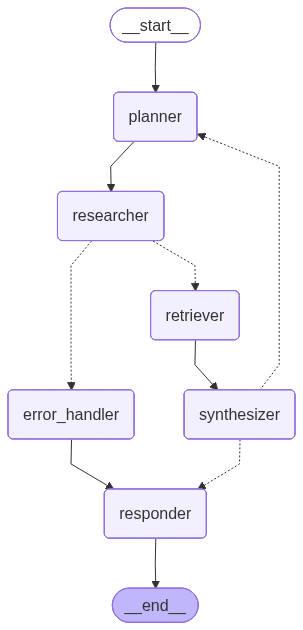

In [2]:
from graph import research_graph

try:
    from IPython.display import Image, display
    display(Image(research_graph.get_graph().draw_mermaid_png()))
except Exception as e:
    print('Could not draw graph. This is safe to ignore. Note:', e)

### 3. Run Turn 1 (Demonstrating Multi-step Queries and Tools)
Watch the [Planner] break down the complex prompt, and the [Researcher] call the web search tool.

In [3]:
from langchain_core.messages import HumanMessage
import uuid

topic = 'What is the Transformer architecture and who introduced it?'
thread_id = str(uuid.uuid4()) # Unique ID for this conversation

initial_state = {
    'messages': [HumanMessage(content=topic)],
    'topic': topic,
    'sub_questions': [],
    'search_results': [],
    'retrieved_docs': [],
    'sources': [],
    'synthesis': '',
    'final_answer': '',
    'turn_count': 0,
    'retry_count': 0,
    'error_message': '',
    'needs_more_research': False,
}

config = {'configurable': {'thread_id': thread_id}}

print(f'Starting research for topic: "{topic}"\n')

for event in research_graph.stream(initial_state, config=config):
    for node_name, state_update in event.items():
        print(f'\n✅ Node executed: [{node_name}]')
        if node_name == 'planner' and 'sub_questions' in state_update:
            print('   Generated Sub-questions:', state_update['sub_questions'])
        elif node_name == 'researcher':
            print(f'   Accumulated {len(state_update.get("search_results", []))} web search results.')
        elif node_name == 'retriever':
            print(f'   Found {len(state_update.get("retrieved_docs", []))} local documents.')
        elif node_name == 'synthesizer':
            print(f'   Needs more research? {state_update.get("needs_more_research", False)}')

final_state = research_graph.get_state(config).values
print('\nFINAL ANSWER\n' + '='*60)
print(final_state.get('final_answer', 'No answer generated.'))


Starting research for topic: "What is the Transformer architecture and who introduced it?"


[Planner] Decomposing topic: 'What is the Transformer architecture and who introduced it?' (turn 1)
[Planner] Generated 3 sub-questions:
  1. Who are the authors of the 2017 paper Attention Is All You Need?
  2. What are the core components and mechanisms of the Transformer architecture?
  3. How does the self-attention mechanism work in the Transformer model?

✅ Node executed: [planner]
   Generated Sub-questions: ['Who are the authors of the 2017 paper Attention Is All You Need?', 'What are the core components and mechanisms of the Transformer architecture?', 'How does the self-attention mechanism work in the Transformer model?']

[Researcher] Running 3 Tavily search(es)...
  -> Searching: 'Who are the authors of the 2017 paper Attention Is All You Need?'


c:\Users\jingy\Downloads\suduAIPretask\tools\search_tools.py:33: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  return TavilySearchResults(


    [+] Got 4 result(s).
  -> Searching: 'What are the core components and mechanisms of the Transformer architecture?'
    [+] Got 4 result(s).
  -> Searching: 'How does the self-attention mechanism work in the Transformer model?'
    [+] Got 4 result(s).
[Researcher] Total results collected: 12
[Router] retry_count=0 -> routing to retriever

✅ Node executed: [researcher]
   Accumulated 12 web search results.

[Retriever] Querying vector store with 4 query/queries...
[Retriever] Retrieved 3 unique document(s) from vector store.
  -> Transformer Architecture (internal://docs/transformer)
  -> Computer Vision and CNNs (internal://docs/cv_cnns)
  -> Prompt Engineering Best Practices (internal://docs/prompt_engineering)

✅ Node executed: [retriever]
   Found 3 local documents.

[Synthesizer] Merging 12 web results + 3 local docs...
[Synthesizer] Built context from 15 unique source(s).
[Synthesizer] Sufficiency check -> sufficient=True
[Router] needs_more_research=False, turn=1 -> responde

### 4. Run Turn 2 (Demonstrating Memory Across Turns)
Notice how the prompt below says "that specific architecture" but doesn't mention the word "Transformer". Because we use the exact same config (with the same thread_id), the agent remembers what we talked about in Turn 1!

In [4]:
follow_up_topic = 'What are some limitations of that specific architecture?'

# Notice we append to the existing state rather than recreating it entirely
follow_up_state = {
    'messages': [HumanMessage(content=follow_up_topic)],
    'topic': follow_up_topic,
    # Reset some turn-specific fields for the new loop
    'sub_questions': [],
    'search_results': [],
    'retrieved_docs': [],
    'turn_count': 0, 
}

print(f'Starting Follow-Up Research: "{follow_up_topic}"\n')

# Stream the graph using the same 'config' to load memory
for event in research_graph.stream(follow_up_state, config=config):
    for node_name, state_update in event.items():
        print(f'\n✅ Node executed: [{node_name}]')
        if node_name == 'planner' and 'sub_questions' in state_update:
            print('   Generated Sub-questions:', state_update['sub_questions'])

final_state = research_graph.get_state(config).values
print('\nFOLLOW-UP ANSWER\n' + '='*60)
print(final_state.get('final_answer', 'No answer generated.'))

Starting Follow-Up Research: "What are some limitations of that specific architecture?"


[Planner] Decomposing topic: 'What are some limitations of that specific architecture?' (turn 1)
[Planner] Generated 4 sub-questions:
  1. What are the computational complexity limitations of the Transformer self-attention mechanism regarding sequence length?
  2. What are the primary memory and hardware constraints associated with scaling Transformer models?
  3. What are the known limitations of Transformers in handling long-range dependencies and context window sizes?
  4. What are the challenges regarding the interpretability and explainability of Transformer-based architectures?

✅ Node executed: [planner]
   Generated Sub-questions: ['What are the computational complexity limitations of the Transformer self-attention mechanism regarding sequence length?', 'What are the primary memory and hardware constraints associated with scaling Transformer models?', 'What are the known limitations of Tra